# Import

In [89]:
import gymnasium as gym
import csv
from pathlib import Path
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from stable_baselines3 import DQN
from stable_baselines3.common.evaluation import evaluate_policy

## Un épisode aléatoire

In [90]:
env = gym.make("LunarLander-v3")

etat_actuel, info = env.reset(seed=42)

total_reward = 0.0
steps = 0

while True:
    action = env.action_space.sample()

    next_state, reward, terminated, truncated, info = env.step(action)

    total_reward += reward
    steps += 1

    etat_actuel = next_state

    if terminated or truncated:
        break

print("Score total :", total_reward)
print("Nombre de pas :", steps)
print("Terminé :", terminated)
print("Interrompu :", truncated)

env.close()

Score total : -154.432288718705
Nombre de pas : 118
Terminé : True
Interrompu : False


## Plusieurs épisodes aléatoires

In [91]:
# Nombre d'épisodes à exécuter (Les épisodes sont les "simulations" qui se termine lorsque le module c'est posé, c'est craché ou à mis trop de temps)
N_EPISODES = 10

# Création de l'environnement sans affichage graphique
env = gym.make("LunarLander-v3")

# Initialisation de la graine aléatoire
env.reset(seed=42)
env.action_space.seed(42)

# On va créer un CSV afin de sauvergarder les résultats
fichier_final = Path("results_random.csv")

# Liste qui contiendra les résultats des épisodes
results = []

# Exécution des épisodes
for episode in range(1, N_EPISODES + 1):

    # Démarrage d'un nouvel épisode
    etat_actuel, info = env.reset()

    # On initialise les récompenses et les "pas" nombre de frame pris par le module jusqu'à terminer l'épisode.
    recompense_totale = 0.0
    steps = 0

    # On initialise terminated et truncated à false (terminated = Posé / Crash / sorti de l'écran | truncated = trop de temps)  
    terminated = False
    truncated = False

    # L'agent joue jusqu'à la fin de l'épisode
    while not (terminated or truncated):

        # Choix d'une action aléatoire
        action = env.action_space.sample()

        # Exécution de l'action (on sauvergarde chaque info qu'engendre l'action comme la position, la récompense ou savoir si le module a terminé d'une quelconque façon)
        next_state, reward, terminated, truncated, info = env.step(action)

        # Mise à jour des statistiques
        recompense_totale += reward
        steps += 1

        # Passage au nouvel état
        etat_actuel = next_state

    # On enregistre les résultats de l'épisode
    result = {
        "episode": episode,
        "reward": round(recompense_totale, 2),
        "steps": steps,
        "terminated": terminated,
        "truncated": truncated
    }

    results.append(result)

    # Affichage du résultat
    print(f"Épisode {episode}/{N_EPISODES} | "f"Récompense obtenue : {recompense_totale:.2f} | "f"Pas utilisés pour terminé : {steps} | "f"Terminé ? : {terminated} | "f"Interrompu ? : {truncated}")

# Fermeture de l'environnement
env.close()

# Ecriture des résultat dans le CSV afin de pouvoir les réutiliser pour des graphiques
with fichier_final.open("w", newline="", encoding="utf-8") as file:

    # Création des 5 colonnes qui sont les différentes paramètres du modèle
    colonnes = ["episode", "reward", "steps", "terminated", "truncated"]

    writer = csv.DictWriter(file, fieldnames=colonnes)

    # writeheader permet d'écrire les noms des colonnes enregistrer dans le paramètres fieldnames
    writer.writeheader()
    writer.writerows(results)

# Calcul des statistiques globales
mean_reward = sum(r["reward"] for r in results) / len(results)

print("\n------- BILAN -------")
print(f"Nombre d'épisodes : {N_EPISODES}")
print(f"Récompense moyenne : {mean_reward:.2f}")

Épisode 1/10 | Récompense obtenue : -108.55 | Pas utilisés pour terminé : 106 | Terminé ? : True | Interrompu ? : False
Épisode 2/10 | Récompense obtenue : -117.45 | Pas utilisés pour terminé : 75 | Terminé ? : True | Interrompu ? : False
Épisode 3/10 | Récompense obtenue : -304.18 | Pas utilisés pour terminé : 62 | Terminé ? : True | Interrompu ? : False
Épisode 4/10 | Récompense obtenue : -113.35 | Pas utilisés pour terminé : 101 | Terminé ? : True | Interrompu ? : False
Épisode 5/10 | Récompense obtenue : -108.74 | Pas utilisés pour terminé : 105 | Terminé ? : True | Interrompu ? : False
Épisode 6/10 | Récompense obtenue : -295.99 | Pas utilisés pour terminé : 87 | Terminé ? : True | Interrompu ? : False
Épisode 7/10 | Récompense obtenue : -116.40 | Pas utilisés pour terminé : 101 | Terminé ? : True | Interrompu ? : False
Épisode 8/10 | Récompense obtenue : -222.88 | Pas utilisés pour terminé : 143 | Terminé ? : True | Interrompu ? : False
Épisode 9/10 | Récompense obtenue : -100.74

## Graphiques des résultats

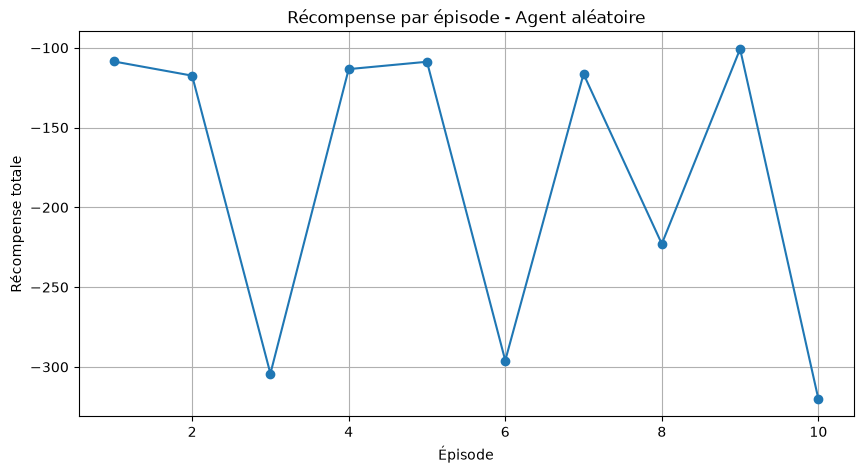

In [92]:
# On initialise deux listes qui vont contenir les informations nécessaire au graphique (Ici, les récompenses par épisode)
episodes = []
rewards = []

# Lecture du fichier CSV
with open("results_random.csv", "r", encoding="utf-8") as file:
    reader = csv.DictReader(file)

    # Pour chaque ligne du CSV, on ajoute l'épisode et la récompense associée, à la liste    
    for row in reader:
        episodes.append(int(row["episode"]))
        rewards.append(float(row["reward"]))

# Création du graphique
plt.figure(figsize=(10, 5))

# Ordonnées episodes, Abscisses récompenses
plt.plot(episodes, rewards, marker="o")

# Légende du graphique (titre, label X, label Y)
plt.title("Récompense par épisode - Agent aléatoire")
plt.xlabel("Épisode")
plt.ylabel("Récompense totale")

# On affiche une grille pour pouvoir exploiter plus simplement le graphique
plt.grid(True)
plt.show()

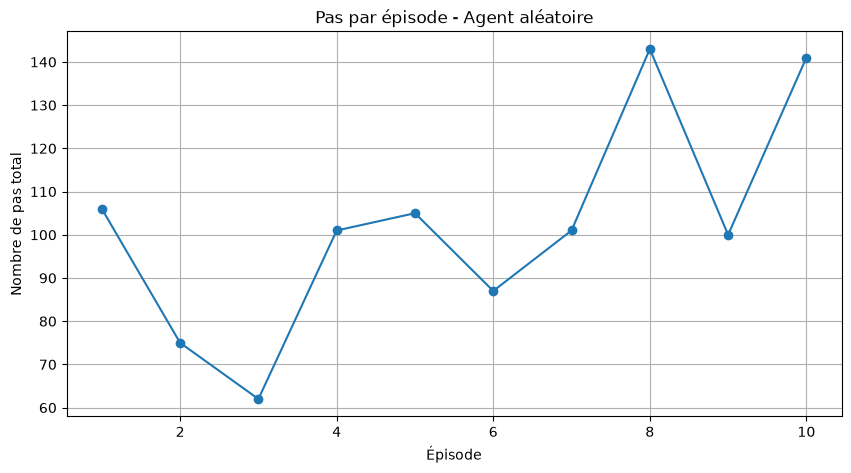

In [93]:
# On initialise deux listes qui vont contenir les informations nécessaire au graphique (Ici, les pas par épisode)
episodes = []
steps = []

# Lecture du fichier CSV
with open("results_random.csv", "r", encoding="utf-8") as file:
    reader = csv.DictReader(file)

    # Pour chaque ligne du CSV, on ajoute l'épisode et le nombre de pas à la liste
    for ligne in reader:
        episodes.append(int(ligne["episode"]))
        steps.append(float(ligne["steps"]))

# Création du graphique
plt.figure(figsize=(10, 5))

# Ordonnées episodes, Abscisses Steps
plt.plot(episodes, steps, marker="o")

# Légende du graphique (titre, label X, label Y)
plt.title("Pas par épisode - Agent aléatoire")
plt.xlabel("Épisode")
plt.ylabel("Nombre de pas total")

# On affiche une grille pour pouvoir exploiter plus simplement le graphique
plt.grid(True)
plt.show()

## Entrainement DQN

### Création de l'environnement PyTorch

In [94]:
class DQN(nn.Module):
    def __init__(self, state_size=8, action_size=4):
        super(DQN, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(state_size, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, action_size)
        )

    def forward(self, state):
        return self.network(state)

### Epsilon-greedy

### ReplayBuffer

In [96]:
# Nombre d'épisodes à exécuter (Les épisodes sont les "simulations" qui se termine lorsque le module c'est posé, c'est craché ou à mis trop de temps)
N_EPISODES = 10

# Création de l'environnement sans affichage graphique
env = gym.make("LunarLander-v3")

# Initialisation de la graine aléatoire
env.reset(seed=42)
env.action_space.seed(42)

# On va créer un CSV afin de sauvergarder les résultats
fichier_final = Path("results_random.csv")

# Liste qui contiendra les résultats des épisodes
results = []

model = DQN()
# Exécution des épisodes
for episode in range(1, N_EPISODES + 1):

    # Démarrage d'un nouvel épisode
    etat_actuel, info = env.reset()

    # On initialise les récompenses et les "pas" nombre de frame pris par le module jusqu'à terminer l'épisode.
    recompense_totale = 0.0
    steps = 0

    # On initialise terminated et truncated à false (terminated = Posé / Crash / sorti de l'écran | truncated = trop de temps)  
    terminated = False
    truncated = False

    # L'agent joue jusqu'à la fin de l'épisode
    while not (terminated or truncated):

        state = torch.tensor(etat_actuel)
        q_values = model(state)

        action = torch.argmax(q_values).item()

        # Exécution de l'action (on sauvergarde chaque info qu'engendre l'action comme la position, la récompense ou savoir si le module a terminé d'une quelconque façon)
        next_state, reward, terminated, truncated, info = env.step(action)

        # Mise à jour des statistiques
        recompense_totale += reward
        steps += 1

        # Passage au nouvel état
        etat_actuel = next_state

    # On enregistre les résultats de l'épisode
    result = {
        "episode": episode,
        "reward": round(recompense_totale, 2),
        "steps": steps,
        "terminated": terminated,
        "truncated": truncated
    }

    results.append(result)

    # Affichage du résultat
    print(f"Épisode {episode}/{N_EPISODES} | "f"Récompense obtenue : {recompense_totale:.2f} | "f"Pas utilisés pour terminé : {steps} | "f"Terminé ? : {terminated} | "f"Interrompu ? : {truncated}")

# Fermeture de l'environnement
env.close()

# Ecriture des résultat dans le CSV afin de pouvoir les réutiliser pour des graphiques
with fichier_final.open("w", newline="", encoding="utf-8") as file:

    # Création des 5 colonnes qui sont les différentes paramètres du modèle
    colonnes = ["episode", "reward", "steps", "terminated", "truncated"]

    writer = csv.DictWriter(file, fieldnames=colonnes)

    # writeheader permet d'écrire les noms des colonnes enregistrer dans le paramètres fieldnames
    writer.writeheader()
    writer.writerows(results)

# Calcul des statistiques globales
mean_reward = sum(r["reward"] for r in results) / len(results)

print("\n------- BILAN -------")
print(f"Nombre d'épisodes : {N_EPISODES}")
print(f"Récompense moyenne : {mean_reward:.2f}")

print("État :", state)
print("Q-values :", q_values)
print("Nombre d'actions :", len(q_values))

Épisode 1/10 | Récompense obtenue : -151.73 | Pas utilisés pour terminé : 74 | Terminé ? : True | Interrompu ? : False
Épisode 2/10 | Récompense obtenue : -159.82 | Pas utilisés pour terminé : 80 | Terminé ? : True | Interrompu ? : False
Épisode 3/10 | Récompense obtenue : -126.60 | Pas utilisés pour terminé : 86 | Terminé ? : True | Interrompu ? : False
Épisode 4/10 | Récompense obtenue : -139.02 | Pas utilisés pour terminé : 68 | Terminé ? : True | Interrompu ? : False
Épisode 5/10 | Récompense obtenue : -119.01 | Pas utilisés pour terminé : 68 | Terminé ? : True | Interrompu ? : False
Épisode 6/10 | Récompense obtenue : -142.30 | Pas utilisés pour terminé : 77 | Terminé ? : True | Interrompu ? : False
Épisode 7/10 | Récompense obtenue : -135.45 | Pas utilisés pour terminé : 78 | Terminé ? : True | Interrompu ? : False
Épisode 8/10 | Récompense obtenue : -137.63 | Pas utilisés pour terminé : 78 | Terminé ? : True | Interrompu ? : False
Épisode 9/10 | Récompense obtenue : -158.75 | Pa